In [1]:
import findspark

In [2]:
findspark.init("/opt/manual/spark")

In [3]:
from pyspark.sql import SparkSession, functions as F
import pandas as pd

In [4]:
spark = SparkSession.builder \
.appName("KMenas") \
.master("yarn") \
.config("spark.sql.shuffle.partitions","2") \
.getOrCreate()

In [5]:
spark.version

'3.1.1'

In [6]:
! hdfs dfs -ls /user/train/datasets | grep Churn_Modelling

-rw-r--r--   1 train supergroup     674857 2021-10-09 10:43 /user/train/datasets/Churn_Modelling.csv


## Read train data

In [7]:
df = spark.read.format("csv") \
.option("header", True) \
.option("inferSchema", True) \
.load("hdfs://localhost:9000/user/train/datasets/Churn_Modelling.csv")

## Explore train data

In [8]:
pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)

In [9]:
df.limit(6).toPandas()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,6,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1


In [10]:
df.printSchema()

root
 |-- RowNumber: integer (nullable = true)
 |-- CustomerId: integer (nullable = true)
 |-- Surname: string (nullable = true)
 |-- CreditScore: integer (nullable = true)
 |-- Geography: string (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Tenure: integer (nullable = true)
 |-- Balance: double (nullable = true)
 |-- NumOfProducts: integer (nullable = true)
 |-- HasCrCard: integer (nullable = true)
 |-- IsActiveMember: integer (nullable = true)
 |-- EstimatedSalary: double (nullable = true)
 |-- Exited: integer (nullable = true)



In [11]:
# Schema change analysis
# spark inference is consistent

In [12]:
df.persist()

DataFrame[RowNumber: int, CustomerId: int, Surname: string, CreditScore: int, Geography: string, Gender: string, Age: int, Tenure: int, Balance: double, NumOfProducts: int, HasCrCard: int, IsActiveMember: int, EstimatedSalary: double, Exited: int]

In [13]:
df_count = df.count()
print(df_count)

10000


In [14]:
len(df.columns)

14

# null check

In [15]:
# Null check
for col_name in df.dtypes:
    null_count = df.filter( (F.col(col_name[0]).isNull()) | (F.col(col_name[0]) == "")).count()
    if(  null_count > 0 ):
        print("{} {} type has {} null values % {}".format(col_name, col_type[1], null_count, (null_count/df_count * 100)))

In [16]:
# There is no null

# Group columns

In [17]:
categoric_cols = []
numeric_cols = []
discarted_cols = ['RowNumber','CustomerId','Surname']
label_col = ['Exited']

In [18]:
# column seperation
for col_name in df.dtypes:
    if (col_name[0] not in label_col+discarted_cols):
        if (col_name[1] == 'string'):
            categoric_cols.append(col_name[0])
        else: numeric_cols.append(col_name[0])

In [19]:
print(numeric_cols)
print(len(numeric_cols))

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
8


In [20]:
print(categoric_cols)
print(len(categoric_cols))

['Geography', 'Gender']
2


In [21]:
print(discarted_cols)
print(len(discarted_cols))

['RowNumber', 'CustomerId', 'Surname']
3


In [22]:
print(label_col)
print(len(label_col))

['Exited']
1


#  trim string columns

In [23]:
for col_name in categoric_cols:
    df1 = df.withColumn(col_name, F.trim(col_name))

# Distribution of Output/Target variable

In [24]:
df1.select(label_col[0]).groupBy(label_col[0]).count().show()

+------+-----+
|Exited|count|
+------+-----+
|     1| 2037|
|     0| 7963|
+------+-----+



<AxesSubplot:>

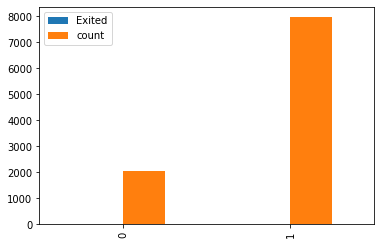

In [25]:
df1.select(label_col[0]).groupBy(label_col[0]).count().toPandas().plot(kind='bar')

# Examine Categoricals

In [26]:
for col_name in categoric_cols:
    df1.groupBy(col_name).agg(F.count("*").alias("TotalCount")).orderBy(F.desc("TotalCount")).show()

+---------+----------+
|Geography|TotalCount|
+---------+----------+
|   France|      5014|
|  Germany|      2509|
|    Spain|      2477|
+---------+----------+

+------+----------+
|Gender|TotalCount|
+------+----------+
|  Male|      5457|
|Female|      4543|
+------+----------+



## verification of columns

In [27]:
if len(df1.columns) == (len(categoric_cols)+len(numeric_cols)+len(discarted_cols+label_col)):
    print("Columns verified")
else: print("Columns are not verified")

Columns verified


## Select columns for onehotencoder

In [28]:
# Here we count the distinct categories in categoric columns. If there is more than two,
# we will add those to to_be_onehotencoded_cols list If there is just 2 we don't need to use onehotencoder
# So if distinct category gt 2 we have to add it to_be_onehotencoded_cols list
to_be_onehotencoded_cols = []

for col_name in categoric_cols:
    count = df1.select(col_name).distinct().count()
    if count > 2:
        to_be_onehotencoded_cols.append(col_name)
    print("{} has {} distinct category.".format(col_name, count))
    

Geography has 3 distinct category.
Gender has 2 distinct category.


In [29]:
print(to_be_onehotencoded_cols)

['Geography']


# StringIndexer

In [30]:
from pyspark.ml.feature import StringIndexer

In [31]:
# Will hold stringIndexer objects and column names
my_dict = {}

# Will collect StringIndexer ojects
string_indexer_objs = []

# Will collect StringIndexer output colnames
string_indexer_output_names = []

# Will collect OneHotEncoder output colnames
ohe_col_input_names = []
ohe_col_output_names = []

for col_name in categoric_cols:
    my_dict[col_name+"_indexobj"] = StringIndexer() \
    .setHandleInvalid('skip') \
    .setInputCol(col_name) \
    .setOutputCol(col_name+"_indexed")
    
    string_indexer_objs.append(my_dict.get(col_name+"_indexobj"))
    string_indexer_output_names.append(col_name+"_indexed")
    if col_name in to_be_onehotencoded_cols:
        ohe_col_input_names.append(col_name+"_indexed")
        ohe_col_output_names.append(col_name+"_ohe")

In [32]:
print(string_indexer_objs)
print(len(string_indexer_objs))

[StringIndexer_4503bce06976, StringIndexer_5ffef5f13451]
2


In [33]:
print(string_indexer_output_names)
print(len(string_indexer_output_names))

['Geography_indexed', 'Gender_indexed']
2


In [34]:
print(ohe_col_input_names)
print(len(ohe_col_input_names))

['Geography_indexed']
1


In [35]:
print(ohe_col_output_names)
print(len(ohe_col_output_names))

['Geography_ohe']
1


# OnehotEncoder

In [36]:
from pyspark.ml.feature import OneHotEncoder

In [37]:
encoder = OneHotEncoder() \
.setInputCols(ohe_col_input_names) \
.setOutputCols(ohe_col_output_names)

# VectorAssembler

In [38]:
from pyspark.ml.feature import VectorAssembler

In [39]:
# We have to exclude onehotencoded categoric cols from stringIndexer cols
string_indexer_col_names_ohe_exluded = list(set(string_indexer_output_names).difference(set(ohe_col_input_names)))
string_indexer_col_names_ohe_exluded

['Gender_indexed']

## column verification

In [40]:
if len(categoric_cols) == (len(string_indexer_col_names_ohe_exluded)+len(ohe_col_output_names)):
    print("Columns verified")
else: print("Columns are not verified")

Columns verified


In [41]:
assembler = VectorAssembler().setHandleInvalid("skip") \
.setInputCols(numeric_cols+string_indexer_col_names_ohe_exluded+ohe_col_output_names) \
.setOutputCol('unscaled_features')

# Feature Scaling

In [42]:
from pyspark.ml.feature import StandardScaler

In [43]:
scaler = StandardScaler().setInputCol("unscaled_features").setOutputCol("features")

# PCA

In [44]:
# from pyspark.ml.feature import PCA

In [45]:
# pca = PCA().setInputCol("scaled_features").setK(10).setOutputCol("features")

# Pipeline

In [46]:
from pyspark.ml import Pipeline

In [47]:
pipeline_obj = Pipeline().setStages(string_indexer_objs+[encoder, assembler, scaler])

In [48]:
pipeline_model = pipeline_obj.fit(df1)

In [49]:
transformed_df = pipeline_model.transform(df1)

In [50]:
transformed_df.limit(5).toPandas()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_indexed,Gender_indexed,Geography_ohe,unscaled_features,features
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0.0,1.0,"(1.0, 0.0)","[619.0, 42.0, 2.0, 0.0, 1.0, 1.0, 1.0, 101348....","[6.404333924389993, 4.0046505619078925, 0.6915..."
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,2.0,1.0,"(0.0, 0.0)","[608.0, 41.0, 1.0, 83807.86, 1.0, 0.0, 1.0, 11...","[6.2905250824379895, 3.9093017390053237, 0.345..."
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,0.0,1.0,"(1.0, 0.0)","[502.0, 42.0, 8.0, 159660.8, 3.0, 1.0, 0.0, 11...","[5.193821696355051, 4.0046505619078925, 2.7660..."
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0.0,1.0,"(1.0, 0.0)","[699.0, 39.0, 1.0, 0.0, 2.0, 0.0, 0.0, 93826.6...","[7.232034593131834, 3.718604093200186, 0.34576..."
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,2.0,1.0,"(0.0, 0.0)","[850.0, 43.0, 2.0, 125510.82, 1.0, 1.0, 1.0, 7...","[8.794319605382057, 4.099999384810461, 0.69152..."


# Train Model

In [51]:
from pyspark.ml.clustering import KMeans

In [1]:
def compute_kmeans_model(df, k):
    kmeansObject = KMeans() \
        .setSeed(142) \
        .setK(k) \
        .setPredictionCol("cluster") \
        .setFeaturesCol("features") \
        .setMaxIter(40) \
        .setTol(1.0e-5)
    
    return kmeansObject.fit(df)

# Evaluator

In [2]:
from pyspark.ml.evaluation import ClusteringEvaluator

In [3]:
evaluator = ClusteringEvaluator() \
      .setFeaturesCol("features") \
      .setPredictionCol("cluster") \
      .setMetricName("silhouette")

AttributeError: Cannot load _jvm from SparkContext. Is SparkContext initialized?

In [56]:
for k in range(2,11):
    kmeans_model = compute_kmeans_model(transformed_df, k)
    
    transformed_df2 = kmeans_model.transform(transformed_df)
    
    score = evaluator.evaluate(transformed_df2)
    
    cost = kmeans_model.summary.trainingCost
    
    print("k: {}, Score: {}, Compute cost: {}".format(k, score, cost))

k: 2, Score: 0.24590625242752776, Compute cost: 95190.30707853852
k: 3, Score: 0.22645984369837002, Compute cost: 86388.53392996272
k: 4, Score: 0.21109416946633186, Compute cost: 81421.79276428775
k: 5, Score: 0.2016827064122783, Compute cost: 78996.0797902454
k: 6, Score: 0.18932939099895102, Compute cost: 76010.88584339904
k: 7, Score: 0.18614323383326292, Compute cost: 74269.5581484231
k: 8, Score: 0.17568537664049033, Compute cost: 72682.12192600335
k: 9, Score: 0.1855896305798431, Compute cost: 70322.67908014488
k: 10, Score: 0.1775850152737766, Compute cost: 67619.60823214224


In [56]:
# we pickup k value based on silhouette score the closer to 1 is the better.

# Retrain with best k value

In [57]:
kmeans_model = compute_kmeans_model(transformed_df, 2)

# Save the model

In [58]:
kmeans_model.write().overwrite().save("file:///saved_models/kmeans_model")

# Prediction

In [59]:
transformed_df2 = kmeans_model.transform(transformed_df)

In [60]:
transformed_df2.limit(5).toPandas()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_indexed,Gender_indexed,Geography_ohe,unscaled_features,features,cluster
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0.0,1.0,"(1.0, 0.0)","[619.0, 42.0, 2.0, 0.0, 1.0, 1.0, 1.0, 101348....","[6.404333924389993, 4.0046505619078925, 0.6915...",1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,2.0,1.0,"(0.0, 0.0)","[608.0, 41.0, 1.0, 83807.86, 1.0, 0.0, 1.0, 11...","[6.2905250824379895, 3.9093017390053237, 0.345...",0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,0.0,1.0,"(1.0, 0.0)","[502.0, 42.0, 8.0, 159660.8, 3.0, 1.0, 0.0, 11...","[5.193821696355051, 4.0046505619078925, 2.7660...",1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0.0,1.0,"(1.0, 0.0)","[699.0, 39.0, 1.0, 0.0, 2.0, 0.0, 0.0, 93826.6...","[7.232034593131834, 3.718604093200186, 0.34576...",1
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,2.0,1.0,"(0.0, 0.0)","[850.0, 43.0, 2.0, 125510.82, 1.0, 1.0, 1.0, 7...","[8.794319605382057, 4.099999384810461, 0.69152...",0


In [61]:
transformed_df2.select("Exited","cluster").show()

+------+-------+
|Exited|cluster|
+------+-------+
|     1|      1|
|     0|      0|
|     1|      1|
|     0|      1|
|     0|      0|
|     1|      0|
|     0|      1|
|     1|      0|
|     0|      1|
|     0|      1|
|     0|      1|
|     0|      1|
|     0|      1|
|     0|      1|
|     0|      1|
|     0|      0|
|     1|      0|
|     0|      1|
|     0|      1|
|     0|      1|
+------+-------+
only showing top 20 rows



In [62]:
spark.stop()